In [1]:
import glob 
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from aostools import climate
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)


def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    return ds_djf

def calculate_son_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_son = ds_seasons.sel(time=(ds_seasons['time.season'] == 'SON'))
    return ds_son

def pressure_weighting(data, plevs=slice(7000,2000)):
    # here I select the pressure level intervall 
    # for which I want to caluculate the layer weights
    # (in this case plevs = 70 - 20 hPa)
    data = data.sel(plev=plevs)
    # Then natural logarithm of this pressure values is caluculated
    log_pressure = np.log(data.plev.values)  
    # the difference between this logaritmic pressure values is made
    log_layer_thickness = np.abs(np.diff(log_pressure))
    # then i devide these differences by the total thickness of the layer
    # = sum of the differences
    log_layer_thickness = log_layer_thickness / sum(log_layer_thickness)

    # this part just creates an array to make it compatible with the data 
    # #(no manipulation of the results done in this step)
    log_layer_thickness = xr.DataArray(
        log_layer_thickness,
        coords={"plev": data.plev.values[:-1]},  # Assign to the lower pressure level of each layer
        dims=["plev"]
    )

    # finally I multiply the data with the "normalized" thickness of the pressure layer
    data = data * log_layer_thickness

    return data.sum(dim='plev')

In [2]:
def calculate_tercile_flags(data, var):
    # calculate terciles to cluster indices into 3 categories: -1 (negative/cold), 0 (netural), 1 (positive/warm state)
    df = data[var].to_dataframe()
    df = df.reset_index()
    df = df.set_index('time')
    tertiles = df[var].quantile([1/3, 2/3]).to_list()
    tertiles = [-float('inf')] + tertiles + [float('inf')]

    df['tercile'] = pd.cut(df[var], bins=tertiles, labels=[-1,0,1])
    return df['tercile']

def calculate_index(path, var, time_coder=time_coder):
    # calculate index and tercile flags for a given variable and path (ENSO: var='tos', NAO: var='zg')
    data = xr.open_dataset(path, decode_times=time_coder)
    index = (data - data.mean('time'))/ np.sqrt(data.var('time'))
    index['tercile'] = calculate_tercile_flags(index, var)
    return index


In [3]:
def plot_difference(modelname, data, flags, plotdir='/home/kperny/VolMIP_stratosphere/plots/', levels = np.linspace(-90,-15, 21)):

    fig, axs = plt.subplots(3,4, figsize=(15,10), sharex=True, sharey=True, layout='constrained')

    axs[1,0].set_axis_off()
    axs[2,0].set_axis_off()
    mean = data.ta.mean('time').squeeze()
    m = axs[0,0].contourf(mean.lat, mean.plev, mean - 273.15, levels=levels)

    axs[0,0].set_title('Climatology')
    axs[0,0].set_ylim(10000,1000)
    axs[0,0].set_yscale('log')

    for i, enso in enumerate([0,1,-1]):
        for j, nao in enumerate([0,1,-1]):
            years = flags.where((flags.nao_flag == nao) & (flags.enso_flag == enso)).dropna().index
            tmp = data.sel(time=years).ta.mean('time').squeeze()
            d = axs[i, j+1].contourf(tmp.lat, tmp.plev, tmp - mean, levels=np.linspace(-2,2,19), cmap='coolwarm', extend='both')
            axs[i, j+1].set_title('Climatology - E: ' + str(enso) + '; N: ' + str(nao))
    fig.suptitle('Temperature climatology - ' + modelname, fontsize=14)
    fig.colorbar(m, ax=axs[0,0], location='left')
    fig.colorbar(d, ax=axs[0:3, 3])
    plt.savefig(plotdir + 'background/piControl_ta_difference_' + modelname + '.png', dpi=200)

# def plot_absolute(modelname, data, flags, plotdir='/home/kperny/VolMIP_stratosphere/plots/', levels=np.linspace(-90,-15, 21)):

#     fig, axs = plt.subplots(3,4, figsize=(15,10), sharex=True, sharey=True, layout='constrained')


#     axs[1,0].set_axis_off()
#     axs[2,0].set_axis_off()
#     mean = data.ta.mean('time').squeeze()
#     m = axs[0,0].contourf(mean.lat, mean.plev, mean - 273.15, levels=levels)

#     axs[0,0].set_title('Climatology')
#     axs[0,0].set_ylim(10000,1000)
#     axs[0,0].set_yscale('log')

#     for i, enso in enumerate([0,1,-1]):
#         for j, nao in enumerate([0,1,-1]):
#             years = flags.where((flags.nao_flag == nao) & (flags.enso_flag == enso)).dropna().index
#             tmp = data.sel(time=years).ta.mean('time').squeeze()
#             axs[i, j+1].contourf(tmp.lat, tmp.plev, tmp - 273.15, levels=levels)
#             axs[i, j+1].set_title('Climatology - E: ' + str(enso) + '; N: ' + str(nao))
#     fig.suptitle('Temperature climatology - ' + modelname, fontsize=14)
#     fig.colorbar(m, ax=axs[0:3, 3])
#     plt.savefig(plotdir + 'background/absolute/piControl_ta_absolute_' + modelname + '.png', dpi=200)

In [4]:
path = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G','MPI-ESM1-2-LR', 'MIROC-ES2L', 'UKESM1-0-LL']
colors = ['darkmagenta', 'darkorange', 'royalblue', 'limegreen', 'deepskyblue']
plotdir = '/home/kperny/VolMIP_stratosphere/plots/'
percentage = 0.75

ta_djf = {}
nao_enso = {}
for model in models:
    ta_tmp = xr.open_dataset(glob.glob(path + model + '/ta_AmonZ*.nc')[0], decode_times=time_coder)

    ta_djf[model] = calculate_djf_mean(ta_tmp)
    ta_djf[model]['time'] = pd.date_range(str(ta_djf[model].time[0].values).split('-')[0], str(int(str(ta_djf[model].time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')

    tmp_df = calculate_index(glob.glob(path + model + '/*NAO_djf*.nc')[0], 'zg').to_pandas().tercile.to_frame(name='nao_flag')
    tmp_df['enso_flag'] = calculate_index(glob.glob(path + model + '/*Nino34_djf*.nc')[0], 'tos').to_pandas().tercile
    nao_enso[model] = tmp_df

1
0
1
1
1
0
1


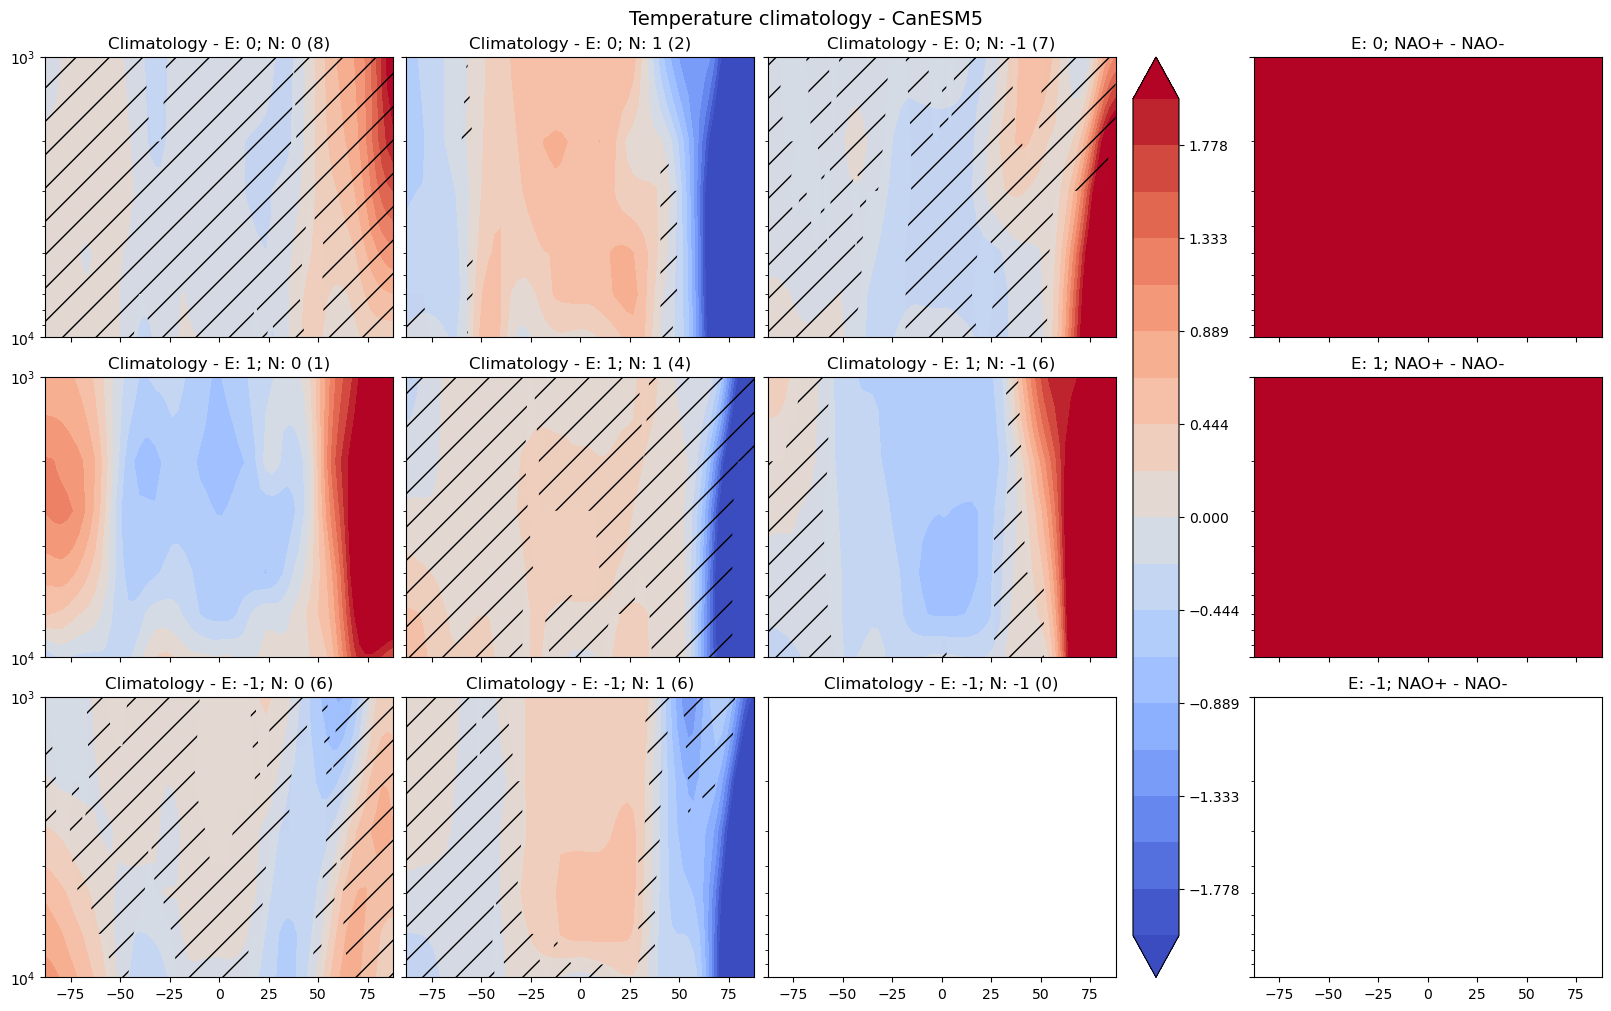

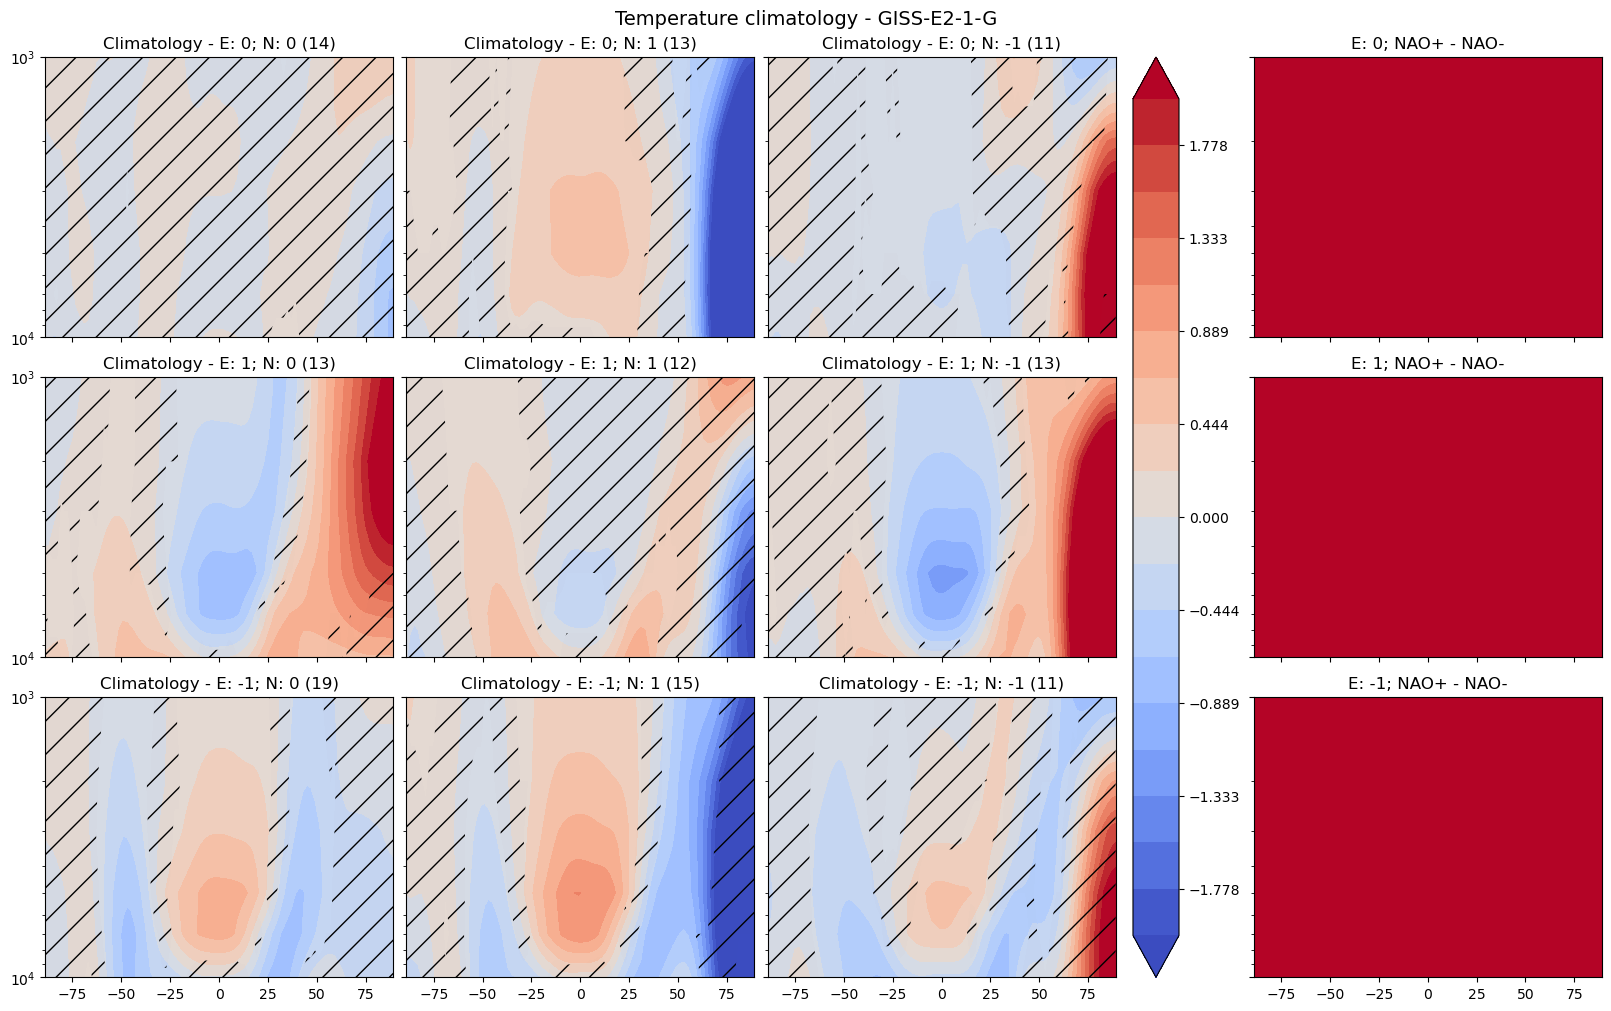

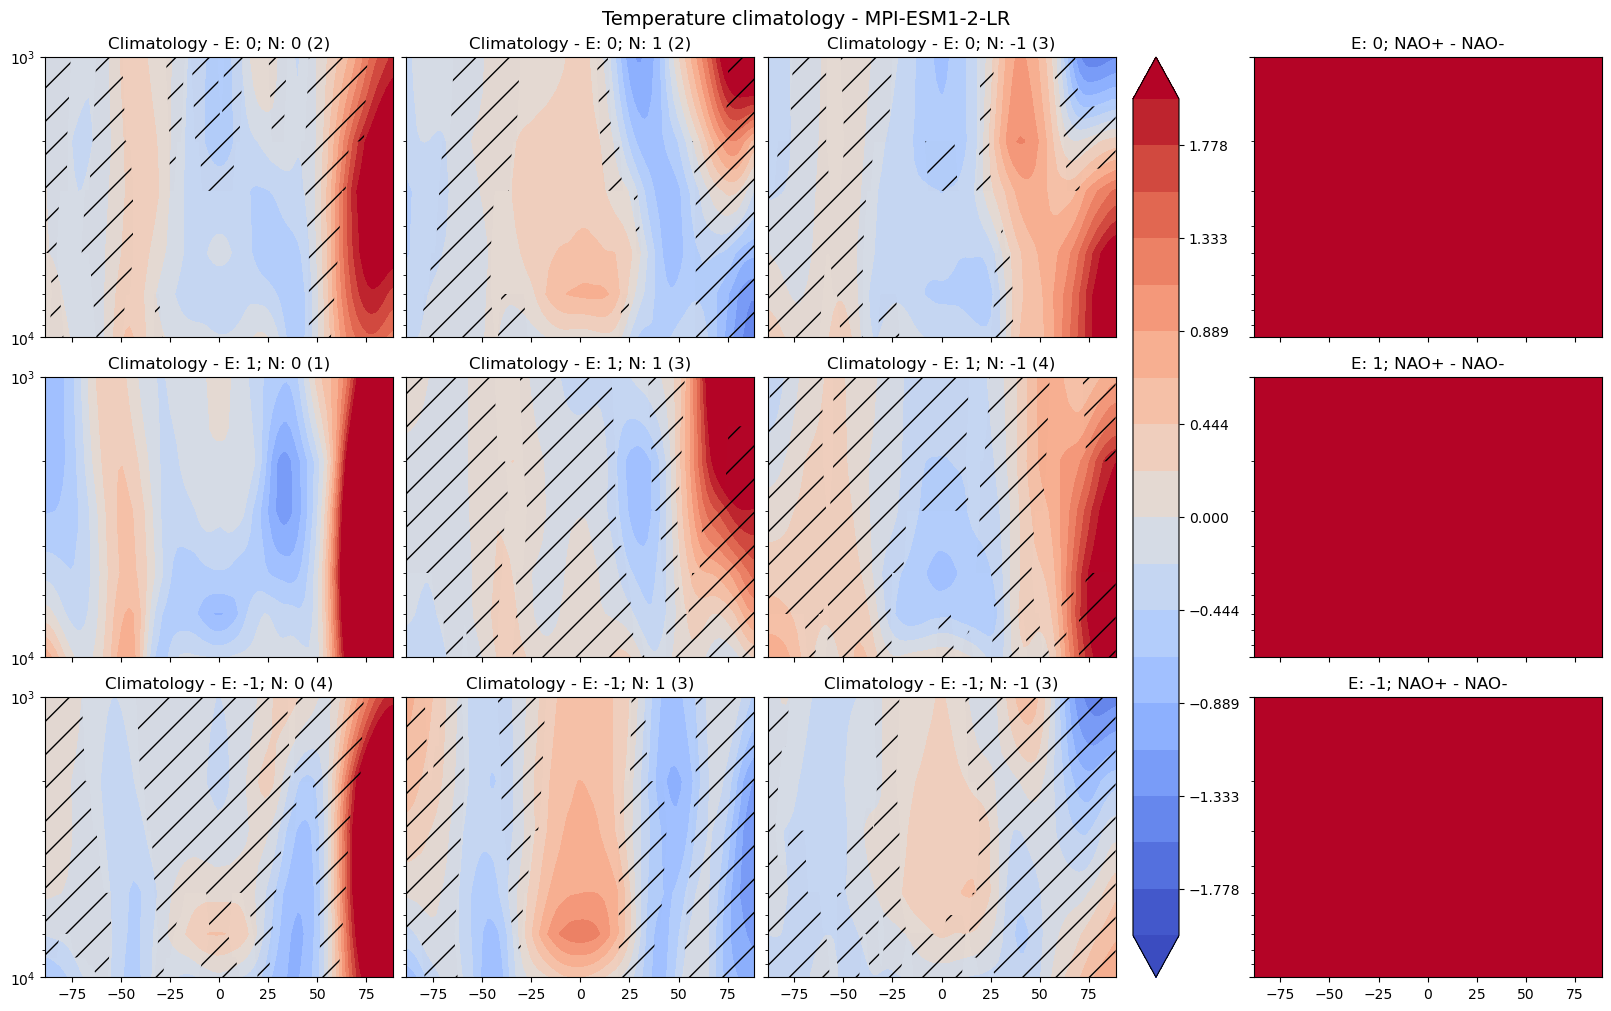

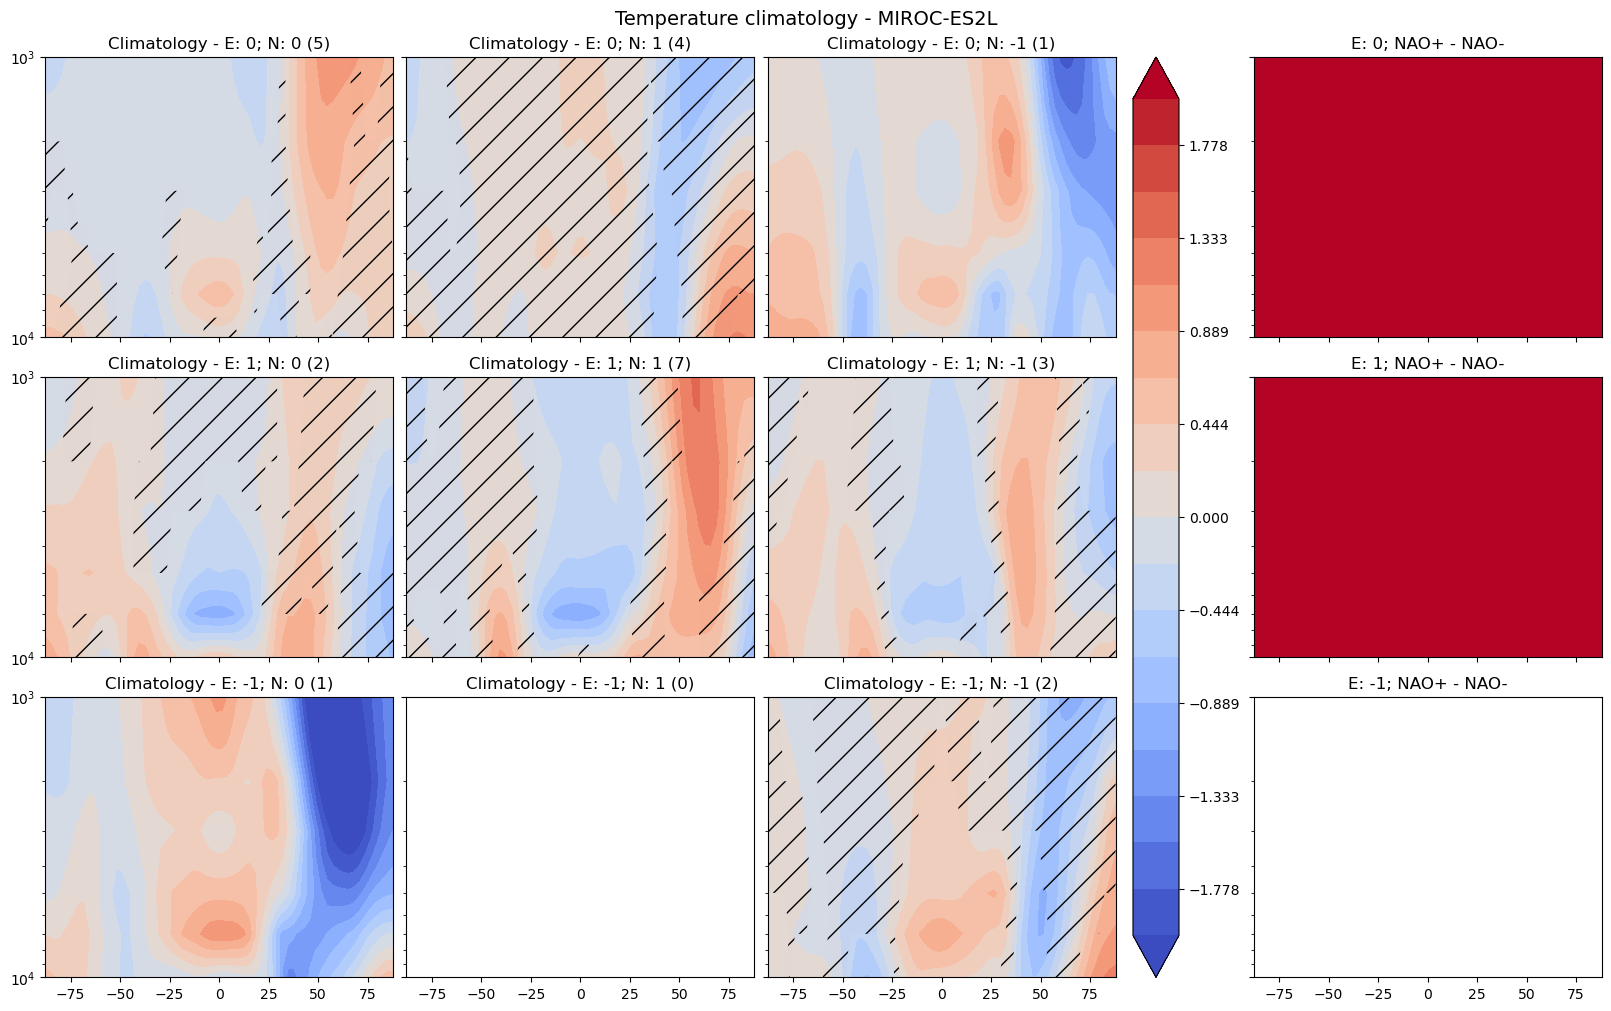

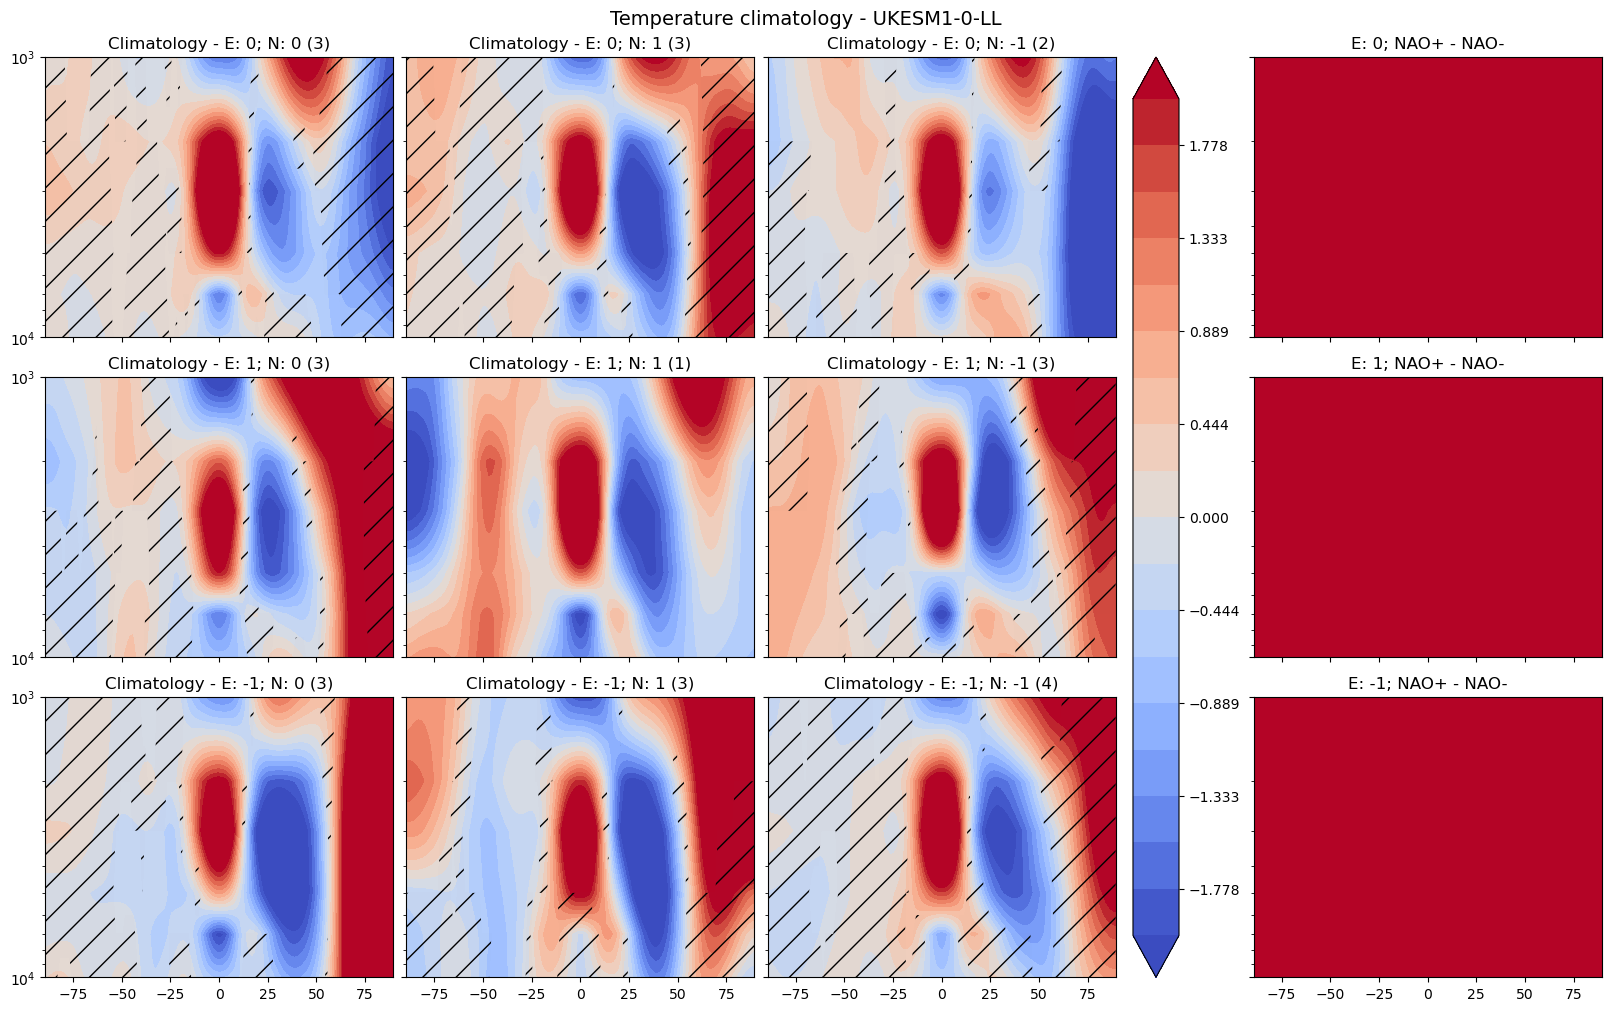

In [ ]:
flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv')

for model in models:
    flags_tmp = flags.where(flags.model == model).dropna()
    data = ta_djf[model]#.sel(time=flags_tmp['year'].values)

    fig, axs = plt.subplots(3,4, figsize=(16,10), sharex=True, sharey=True, layout='constrained')
    levels=np.linspace(-2,2,19)

    mean = data.ta.mean('time').squeeze()

    for i, enso in enumerate([0,1,-1]):
        for j, nao in enumerate([0,1,-1]):
            years = flags_tmp.where((flags_tmp.nao_flag == nao) & (flags_tmp.enso_flag == enso)).dropna()['year'].values
            sign = int(len(years) * percentage)

            tmp = ta_djf[model].sel(time=years).ta.mean('time').squeeze() - mean
            mean_sign = np.sign(tmp)
            data_sign = np.sign(ta_djf[model].sel(time=years).ta.squeeze() - mean)

            d = axs[i, j].contourf(tmp.lat, tmp.plev, tmp, levels=levels, cmap='coolwarm', extend='both')
            try:
                axs[i,j].contourf(tmp.lat, tmp.plev, (data_sign == mean_sign).sum('time'), [0, sign], cmap=plt.get_cmap("gray"), hatches=['/', None], alpha=0.01)
            except:
                print(len(years))
            axs[i, j].set_title('Climatology - E: ' + str(enso) + '; N: ' + str(nao) + ' (' + str(len(years)) + ')')

        years = flags_tmp.where((flags_tmp.nao_flag == 1) & (flags_tmp.enso_flag == enso)).dropna()['year'].values
        naop = ta_djf[model].sel(time=years).ta.mean('time').squeeze()
        axs[i, j+1].contourf(tmp.lat, tmp.plev, naop - tmp + mean, levels=levels, cmap='coolwarm', extend='both')
        axs[i, j+1].set_title('E: ' + str(enso) + '; NAO+ - NAO-') 
    fig.suptitle('Temperature climatology - ' + model, fontsize=14)

    axs[0,0].set_ylim(10000,1000)
    axs[0,0].set_yscale('log')

    fig.colorbar(d, ax=axs[0:3, 2])
    #plt.savefig(plotdir + 'background/piControl_ta_difference_onlyVolMIPyears_' + model + '.png', dpi=200)

In [19]:
nao_enso[model].index

CFTimeIndex([1960-02-30 00:00:00, 1961-02-30 00:00:00, 1962-02-30 00:00:00,
             1963-02-30 00:00:00, 1964-02-30 00:00:00, 1965-02-30 00:00:00,
             1966-02-30 00:00:00, 1967-02-30 00:00:00, 1968-02-30 00:00:00,
             1969-02-30 00:00:00,
             ...
             3831-02-30 00:00:00, 3832-02-30 00:00:00, 3833-02-30 00:00:00,
             3834-02-30 00:00:00, 3835-02-30 00:00:00, 3836-02-30 00:00:00,
             3837-02-30 00:00:00, 3838-02-30 00:00:00, 3839-02-30 00:00:00,
             3840-02-30 00:00:00],
            dtype='object', length=1881, calendar='360_day', freq='YE-FEB')

KeyError: "not all values found in index 'time'"

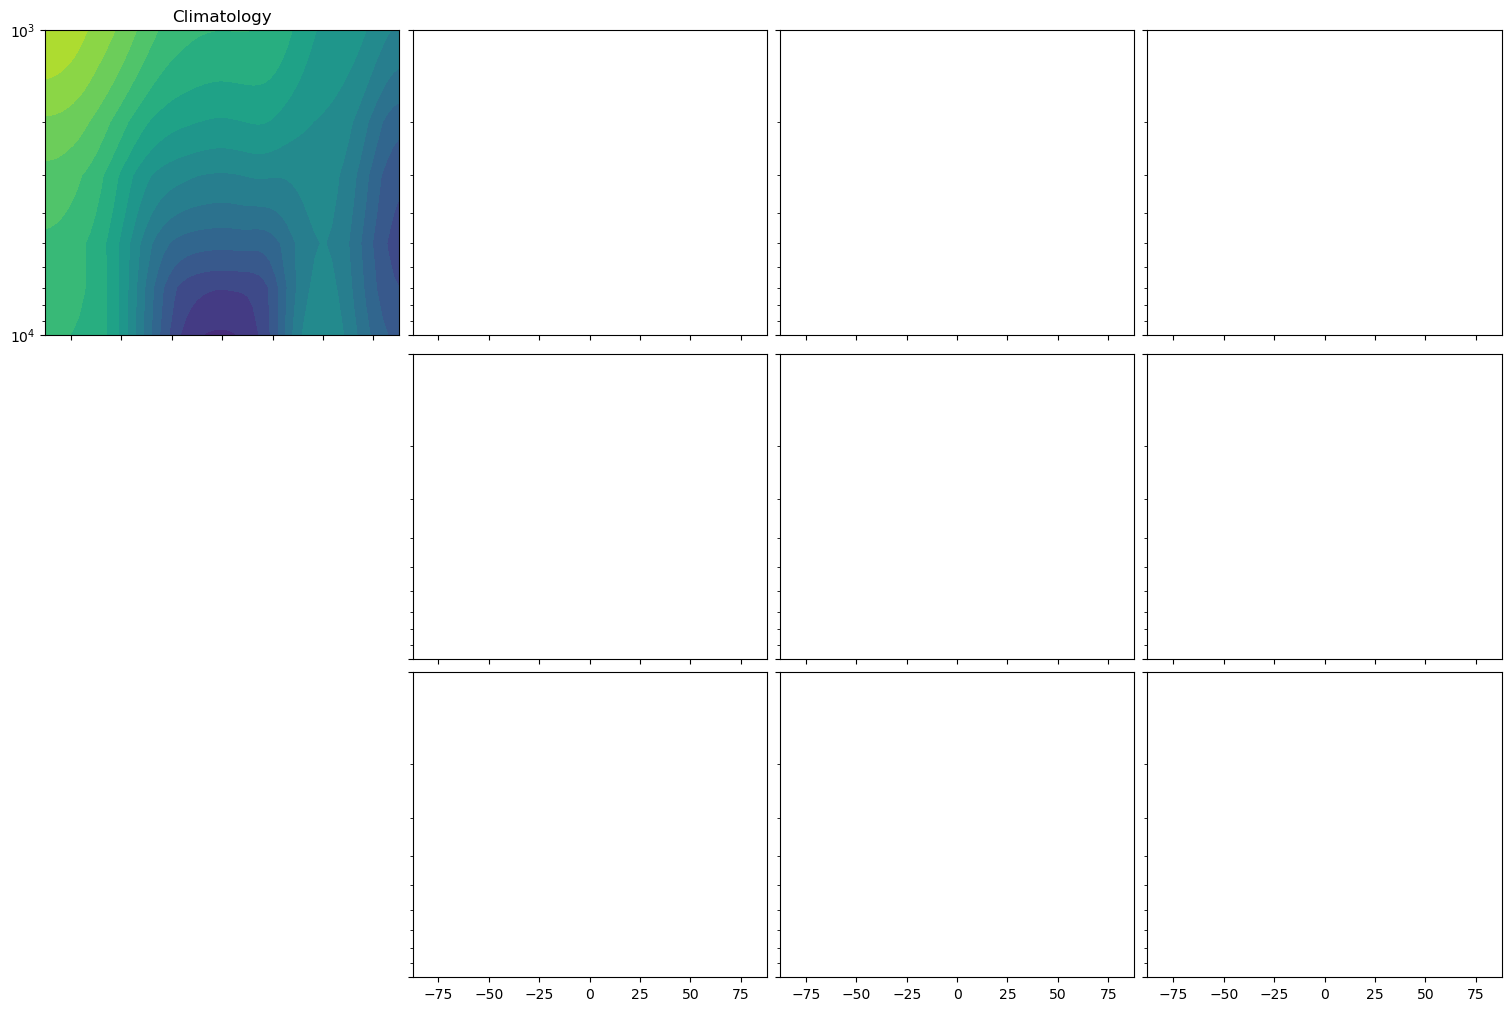

In [9]:
for model in models: 
    plot_difference(model, ta_djf[model], nao_enso[model])
    # plot_absolute(model, ta_djf[model], nao_enso[model])

In [ ]:
path = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G','MPI-ESM1-2-LR', 'MIROC-ES2L', 'UKESM1-0-LL']
colors = ['darkmagenta', 'darkorange', 'royalblue', 'limegreen', 'deepskyblue'] 
plotdir = '/home/kperny/VolMIP_stratosphere/plots/'

ta_djf = {}
ta_son = {}
ua = {}
for model in models:
        ta_tmp = xr.open_dataset(glob.glob(path + model + '/ta_AmonZ*.nc')[0], decode_times=time_coder)
        ta_tmp['time'] = ta_tmp.indexes['time'].to_datetimeindex(time_unit='ms')
        # statospheric temperature 20S-20N 20-70hPa 
        ta_tmp = pressure_weighting(ta_tmp.ta.sel(lat=slice(-20,20))).mean(dim='lat')
        ta_djf[model] = calculate_djf_mean(ta_tmp)
        ta_son[model] = calculate_son_mean(ta_tmp)
        # zonal wind 55N-65N 10hPa
        ua_tmp = xr.open_dataset(glob.glob(path + model + '/ua_AmonZ*.nc')[0], decode_times=time_coder)
        ua[model] = calculate_djf_mean(ua_tmp.ua.sel(lat=slice(55,65), plev=1000).mean(dim='lat'))

/tmp/ipykernel_851255/437104382.py:11: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'noleap', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  ta_tmp['time'] = ta_tmp.indexes['time'].to_datetimeindex(time_unit='ms')
/tmp/ipykernel_851255/437104382.py:11: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'noleap', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  ta_tmp['time'] = ta_tmp.indexes['time'].to_datetimeindex(time_unit='ms')
/tmp/ipykernel_851255/437104382.py:11: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, '360_day', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that

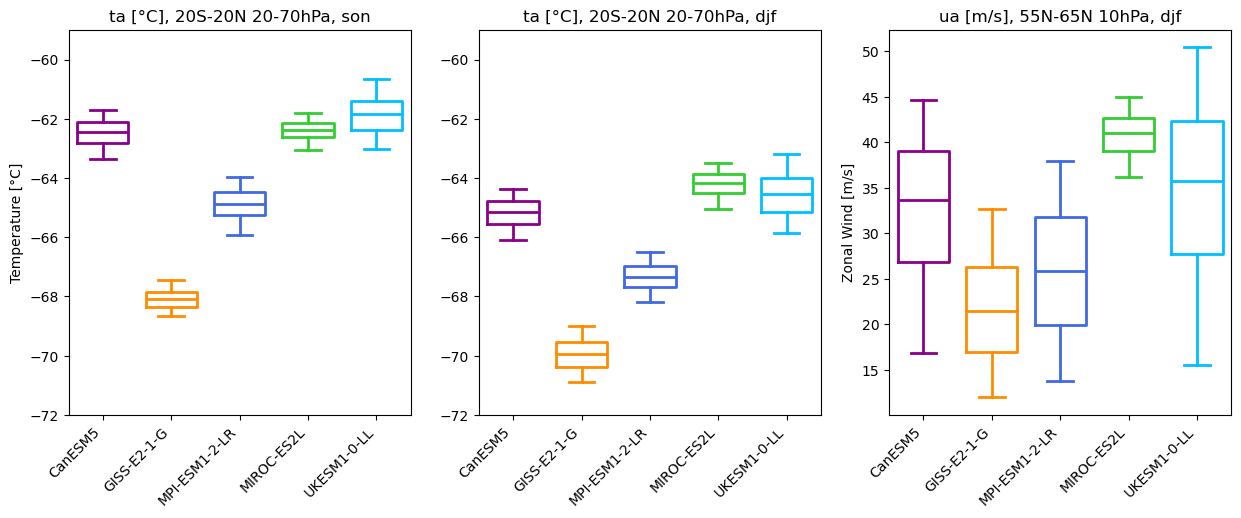

In [14]:
plotdir = '/home/kperny/VolMIP_stratosphere/plots/'
fig, ax = plt.subplots(1,3, figsize=(15,5))

for i, model in enumerate(models):
    ax[0].boxplot(ta_son[model] - 273.15, positions=np.array([i]), whis=(5,95), widths=0.75, showfliers=False,
                boxprops=dict(color=colors[i],linewidth=2), whiskerprops=dict(color=colors[i],linewidth=2),
                capprops=dict(color=colors[i],linewidth=2), medianprops=dict(color=colors[i],linewidth=2))
    ax[1].boxplot(ta_djf[model] - 273.15, positions=np.array([i]), whis=(5,95), widths=0.75, showfliers=False,
                boxprops=dict(color=colors[i],linewidth=2), whiskerprops=dict(color=colors[i],linewidth=2),
                capprops=dict(color=colors[i],linewidth=2), medianprops=dict(color=colors[i],linewidth=2))
    ax[2].boxplot(ua[model], positions=np.array([i]), whis=(5,95), widths=0.75, showfliers=False,
                boxprops=dict(color=colors[i],linewidth=2), whiskerprops=dict(color=colors[i],linewidth=2),
                capprops=dict(color=colors[i],linewidth=2), medianprops=dict(color=colors[i],linewidth=2))

ax[0].set_ylim(-72,-59)
ax[1].set_ylim(-72,-59)

ax[0].set_xticklabels(models)
ax[1].set_xticklabels(models)
ax[2].set_xticklabels(models)
plt.setp( ax[0].xaxis.get_majorticklabels(), rotation=45, horizontalalignment='right')
plt.setp( ax[1].xaxis.get_majorticklabels(), rotation=45, horizontalalignment='right')
plt.setp( ax[2].xaxis.get_majorticklabels(), rotation=45, horizontalalignment='right')
ax[0].set_title('ta [°C], 20S-20N 20-70hPa, son')
ax[1].set_title('ta [°C], 20S-20N 20-70hPa, djf')
ax[2].set_title('ua [m/s], 55N-65N 10hPa, djf')

ax[0].set_ylabel('Temperature [°C]')
#ax[1].set_ylabel('Temperature [°C]')
ax[2].set_ylabel('Zonal Wind [m/s]')

plt.savefig(plotdir + 'background_climate.png', bbox_inches='tight', dpi=200)